# Household Income and Spending in Malaysia
Data: DOSM Household Income and Expenditure Survey.

Soalan bisnes:
1. Daerah mana isi rumah ada baki paling banyak dan paling sedikit selepas belanja?
2. Bagaimana daerah Terengganu berbanding Malaysia?
3. Adakah purata pendapatan ukuran yang adil?
4. Negeri mana pendapatan tumbuh paling laju, 1976 hingga 2024?

Istilah:
Gini: ukuran jurang pendapatan, 0 (sama rata) hingga 1 (tidak sama rata).
Kadar baki: baki selepas belanja, sebagai peratus pendapatan.

In [2]:
import pandas as pd
district = pd.read_csv("https://storage.dosm.gov.my/hies/hies_district.csv")
state = pd.read_csv("https://storage.dosm.gov.my/hies/hh_income_state.csv")
print(district.shape)
print(state.shape)
district.head()

(322, 8)
(319, 4)


,date,state,district,income_mean,income_median,expenditure_mean,gini,poverty
0,2022-01-01,Johor,Batu Pahat,7419,6347,4570,0.338,5.1
1,2024-01-01,Johor,Batu Pahat,9006,7555,5153,0.316,2.4
2,2022-01-01,Johor,Johor Bahru,9869,8232,6139,0.358,3.7
3,2024-01-01,Johor,Johor Bahru,10975,8977,6764,0.350,1.9
4,2022-01-01,Johor,Kluang,6461,5204,4399,0.354,7.2


In [3]:
district.info()
print(district["date"].unique())
print("Bilangan negeri:", district["state"].nunique())
print("Bilangan daerah:", district["district"].nunique())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 322 entries, 0 to 321
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   date              322 non-null    object 
 1   state             322 non-null    object 
 2   district          322 non-null    object 
 3   income_mean       322 non-null    int64  
 4   income_median     322 non-null    int64  
 5   expenditure_mean  322 non-null    int64  
 6   gini              322 non-null    float64
 7   poverty           322 non-null    float64
dtypes: float64(2), int64(3), object(3)
memory usage: 20.3+ KB
['2022-01-01' '2024-01-01']
Bilangan negeri: 16
Bilangan daerah: 172


In [4]:
print("Sel kosong ikut kolum:")
print(district.isna().sum())
print("Baris berulang:", district.duplicated().sum())
district.describe()

Sel kosong ikut kolum:
date                0
state               0
district            0
income_mean         0
income_median       0
expenditure_mean    0
gini                0
poverty             0
dtype: int64
Baris berulang: 0


,income_mean,income_median,expenditure_mean,gini,poverty
count,322.000000,322.000000,322.000000,322.000000,322.000000
mean,6102.391304,4924.599379,3935.173913,0.335127,11.310559
std,2129.471908,1762.591991,1150.968483,0.043669,9.450950
min,2988.000000,2329.000000,2019.000000,0.160000,0.000000
25%,4842.750000,3807.750000,3083.250000,0.308000,4.500000
50%,5454.500000,4441.500000,3676.000000,0.339000,8.800000
75%,6794.750000,5620.500000,4487.000000,0.361000,14.775000
max,15906.000000,12608.000000,8897.000000,0.484000,52.700000


In [5]:
state.info()
print(state["date"].min(), "hingga", state["date"].max())
print(state.isna().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 319 entries, 0 to 318
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   state          319 non-null    object 
 1   date           319 non-null    object 
 2   income_mean    319 non-null    int64  
 3   income_median  308 non-null    float64
dtypes: float64(1), int64(1), object(2)
memory usage: 10.1+ KB
1970-01-01 hingga 2024-01-01
state             0
date              0
income_mean       0
income_median    11
dtype: int64


## Semakan kualiti data:

Jadual daerah: 322 baris, tiada sel kosong, tiada baris berulang.
Jadual negeri: 319 baris, 1970 hingga 2024.

In [6]:
district["date"] = pd.to_datetime(district["date"])
state["date"] = pd.to_datetime(state["date"])
district["year"] = district["date"].dt.year
state["year"] = state["date"].dt.year
print(district["year"].value_counts())

year
2024    162
2022    160
Name: count, dtype: int64


In [7]:
print("Median kosong dalam jadual negeri:")
print(state[state["income_median"].isna()][["state", "year"]])

print("Daerah dengan kemiskinan 0%:")
print(district[district["poverty"] == 0][["year", "state", "district"]])

Median kosong dalam jadual negeri:
               state  year
0              Johor  1970
22             Kedah  1970
44          Kelantan  1970
66            Melaka  1970
88   Negeri Sembilan  1970
110           Pahang  1970
132            Perak  1970
154           Perlis  1970
176     Pulau Pinang  1970
238         Selangor  1970
260       Terengganu  1970
Daerah dengan kemiskinan 0%:
     year     state district
153  2022  Selangor   Sepang


## Isu data dan keputusan:

Median pendapatan tiada untuk 1970 (11 negeri). Analisis pertumbuhan guna purata pendapatan.
Sepang 2022 papar kemiskinan 0.0%, dikekalkan sebagai nilai sah.

In [8]:
district["baki"] = district["income_mean"] - district["expenditure_mean"]
district["kadar_baki"] = district["baki"] / district["income_mean"] * 100
district[["district", "income_mean", "expenditure_mean", "baki", "kadar_baki"]].head(10)

,district,income_mean,expenditure_mean,baki,kadar_baki
0,Batu Pahat,7419,4570,2849,38.401402
1,Batu Pahat,9006,5153,3853,42.782589
2,Johor Bahru,9869,6139,3730,37.795116
3,Johor Bahru,10975,6764,4211,38.369021
4,Kluang,6461,4399,2062,31.914564
5,Kluang,6616,4748,1868,28.234583
6,Kota Tinggi,7529,4498,3031,40.257670
7,Kota Tinggi,8106,4949,3157,38.946459
8,Mersing,5426,4032,1394,25.691117
9,Mersing,6014,4274,1740,28.932491


In [9]:
d2022 = set(district[district["year"] == 2022]["district"])
d2024 = set(district[district["year"] == 2024]["district"])
print("Ada dalam 2024 sahaja:", d2024 - d2022)
print("Ada dalam 2022 sahaja:", d2022 - d2024)

Ada dalam 2024 sahaja: {'Membakut', 'Hulu', 'Lubok antu', 'S.P. Selatan', 'S.P.Tengah', 'Siburan', 'Lingga', 'Pantu', 'Larut & Matang', 'S.P.Utara', 'Gedong', 'Sebuyau'}
Ada dalam 2022 sahaja: {'W.P. Putrajaya', 'Seberang Perai Selatan', 'W.P. Kuala Lumpur', 'Larut Dan Matang', 'Lubok Antu', 'Seberang Perai Tengah', 'Seberang Perai Utara', 'Perlis', 'Hulu Terengganu', 'W.P. Labuan'}


## Data daerah: 2022 (160 daerah) dan 2024 (162 daerah). Perbandingan antara tahun guna daerah yang wujud dalam kedua dua tahun sahaja.

In [10]:
betul = {
    "Lubok antu": "Lubok Antu",
    "S.P. Selatan": "Seberang Perai Selatan",
    "S.P.Tengah": "Seberang Perai Tengah",
    "S.P.Utara": "Seberang Perai Utara",
    "Larut & Matang": "Larut Dan Matang",
}
district["district"] = district["district"].replace(betul)
hulu = (district["state"] == "Terengganu") & (district["district"] == "Hulu")
district.loc[hulu, "district"] = "Hulu Terengganu"

d2022 = set(district[district["year"] == 2022]["district"])
d2024 = set(district[district["year"] == 2024]["district"])
print("Ada dalam 2024 sahaja:", d2024 - d2022)
print("Ada dalam 2022 sahaja:", d2022 - d2024)
print("Bilangan daerah selepas seragam:", district["district"].nunique())

Ada dalam 2024 sahaja: {'Membakut', 'Siburan', 'Lingga', 'Pantu', 'Gedong', 'Sebuyau'}
Ada dalam 2022 sahaja: {'W.P. Kuala Lumpur', 'Perlis', 'W.P. Labuan', 'W.P. Putrajaya'}
Bilangan daerah selepas seragam: 166


## Seragamkan nama daerah
6 daerah ada ejaan berbeza antara 2022 dan 2024, contoh S.P. Selatan dan Seberang Perai Selatan. Nama diseragamkan ikut ejaan 2022. Selepas itu, 6 daerah baru wujud dalam 2024 sahaja, dan 4 kawasan (Perlis, W.P. Kuala Lumpur, Labuan, Putrajaya) tiada dalam data daerah 2024.

In [11]:
print(district.groupby(["state", "year"])["district"].count().unstack())

year               2022  2024
state                        
Johor              10.0  10.0
Kedah              12.0  12.0
Kelantan           11.0  11.0
Melaka              3.0   3.0
Negeri Sembilan     7.0   7.0
Pahang             11.0  11.0
Perak              13.0  13.0
Perlis              1.0   NaN
Pulau Pinang        5.0   5.0
Sabah              27.0  28.0
Sarawak            40.0  45.0
Selangor            9.0   9.0
Terengganu          8.0   8.0
W.P. Kuala Lumpur   1.0   NaN
W.P. Labuan         1.0   NaN
W.P. Putrajaya      1.0   NaN


In [12]:
tahun_terkini = district["year"].max()
terkini = district[district["year"] == tahun_terkini].copy()
print("Tahun:", tahun_terkini, "| Bilangan daerah:", len(terkini))

Tahun: 2024 | Bilangan daerah: 162


In [13]:
kolum = ["state", "district", "income_mean", "expenditure_mean", "baki", "kadar_baki"]
print("10 daerah baki tertinggi:")
print(terkini.sort_values("kadar_baki", ascending=False)[kolum].head(10).round(1).to_string(index=False))
print()
print("10 daerah baki terendah:")
print(terkini.sort_values("kadar_baki")[kolum].head(10).round(1).to_string(index=False))

10 daerah baki tertinggi:
   state     district  income_mean  expenditure_mean  baki  kadar_baki
   Sabah        Kunak         6608              2797  3811        57.7
   Sabah    Kalabakan         5174              2257  2917        56.4
   Sabah Kinabatangan         5632              2482  3150        55.9
   Sabah     Semporna         5604              2567  3037        54.2
   Sabah        Tawau         6751              3182  3569        52.9
Selangor       Sepang        15906              7676  8230        51.7
 Sarawak      Bintulu        10480              5073  5407        51.6
Selangor   Ulu Langat        13822              6758  7064        51.1
 Sarawak       Marudi         5430              2705  2725        50.2
Selangor       Gombak        14168              7326  6842        48.3

10 daerah baki terendah:
          state     district  income_mean  expenditure_mean  baki  kadar_baki
        Sarawak Bukit Mabong         3783              3363   420        11.1
        Sar

In [14]:
median_my = terkini["kadar_baki"].median()
print("Median kadar baki Malaysia:", round(median_my, 1), "%")
trg = terkini[terkini["state"] == "Terengganu"]
print(trg.sort_values("kadar_baki", ascending=False)[kolum].round(1).to_string(index=False))

Median kadar baki Malaysia: 33.5 %
     state         district  income_mean  expenditure_mean  baki  kadar_baki
Terengganu          Kemaman         8973              5644  3329        37.1
Terengganu            Besut         6747              4339  2408        35.7
Terengganu      Kuala Nerus         8385              5498  2887        34.4
Terengganu            Setiu         6359              4314  2045        32.2
Terengganu  Hulu Terengganu         6360              4554  1806        28.4
Terengganu Kuala Terengganu         7279              5264  2015        27.7
Terengganu           Dungun         8055              5833  2222        27.6
Terengganu           Marang         6807              5141  1666        24.5


## Semakan daerah Sabah
Kadar baki purata tertinggi di pantai timur Sabah (Kunak 57.7%). Kadar kemiskinan di sana 26.7% hingga 30.4% dan gini tinggi. Contoh Kalabakan: purata pendapatan RM5,174, median RM3,304. Purata ditarik naik oleh sebilangan kecil isi rumah berpendapatan tinggi. Purata mengelirukan di sini.

## Korelasi
Pendapatan dan gini: 0.03. Tiada hubungan.
Pendapatan dan kemiskinan: -0.52. Daerah berpendapatan tinggi cenderung kurang miskin.
Kemiskinan dan kadar baki: 0.01. Kadar baki purata tidak mencerminkan kemiskinan.

In [15]:
semak = ["state", "district", "income_mean", "income_median", "kadar_baki", "gini", "poverty"]
print(terkini.sort_values("kadar_baki", ascending=False)[semak].head(10).round(2).to_string(index=False))
print()
print("Median kemiskinan Malaysia:", terkini["poverty"].median(), "%")
print("Median gini Malaysia:", round(terkini["gini"].median(), 3))

   state     district  income_mean  income_median  kadar_baki  gini  poverty
   Sabah        Kunak         6608           4539       57.67  0.48     29.2
   Sabah    Kalabakan         5174           3304       56.38  0.45     26.8
   Sabah Kinabatangan         5632           4897       55.93  0.31     26.7
   Sabah     Semporna         5604           4059       54.19  0.41     30.4
   Sabah        Tawau         6751           4852       52.87  0.39     13.2
Selangor       Sepang        15906          11131       51.74  0.33      0.1
 Sarawak      Bintulu        10480           8317       51.59  0.37      3.7
Selangor   Ulu Langat        13822          11404       51.11  0.22      0.1
 Sarawak       Marudi         5430           4519       50.18  0.31      4.4
Selangor       Gombak        14168          10777       48.29  0.37      2.1

Median kemiskinan Malaysia: 8.1 %
Median gini Malaysia: 0.328


In [16]:
print(terkini[["income_mean", "gini", "poverty", "kadar_baki"]].corr().round(2))

             income_mean  gini  poverty  kadar_baki
income_mean         1.00  0.03    -0.52        0.45
gini                0.03  1.00     0.32        0.21
poverty            -0.52  0.32     1.00        0.01
kadar_baki          0.45  0.21     0.01        1.00


In [17]:
terkini["baki_median"] = terkini["income_median"] - terkini["expenditure_mean"]
terkini["kadar_baki_median"] = terkini["baki_median"] / terkini["income_median"] * 100
kolum2 = ["state", "district", "income_median", "expenditure_mean", "baki_median", "kadar_baki_median", "poverty"]

print("Daerah di mana median pendapatan lebih rendah dari purata perbelanjaan:")
print((terkini["baki_median"] < 0).sum(), "daripada", len(terkini), "daerah")
print()
print("10 daerah baki median tertinggi:")
print(terkini.sort_values("kadar_baki_median", ascending=False)[kolum2].head(10).round(1).to_string(index=False))
print()
print("10 daerah baki median terendah:")
print(terkini.sort_values("kadar_baki_median")[kolum2].head(10).round(1).to_string(index=False))
print()
print("Terengganu:")
print(terkini[terkini["state"] == "Terengganu"].sort_values("kadar_baki_median", ascending=False)[kolum2].round(1).to_string(index=False))

Daerah di mana median pendapatan lebih rendah dari purata perbelanjaan:
10 daripada 162 daerah

10 daerah baki median tertinggi:
   state     district  income_median  expenditure_mean  baki_median  kadar_baki_median  poverty
   Sabah Kinabatangan           4897              2482         2415               49.3     26.7
Selangor Kuala Langat          10583              6123         4460               42.1      0.3
   Sabah      Telupid           4489              2659         1830               40.8     22.0
Selangor   Ulu Langat          11404              6758         4646               40.7      0.1
 Sarawak       Marudi           4519              2705         1814               40.1      4.4
 Sarawak      Bintulu           8317              5073         3244               39.0      3.7
   Sabah        Kunak           4539              2797         1742               38.4     29.2
   Sabah      Beluran           4436              2750         1686               38.0     33.0
   Saba

## Baki isi rumah biasa (median pendapatan)
10 daripada 162 daerah ada median pendapatan lebih rendah daripada purata perbelanjaan. Terendah: Bukit Mabong (-29.9%), Pitas (-24.7%), Kota Marudu (-20.5%).
Semua daerah Terengganu positif. Setiu tertinggi (29.6%), Marang terendah (17.7%).
Had: DOSM tidak terbitkan median perbelanjaan. Angka ini guna median pendapatan tolak purata perbelanjaan, jadi ia anggaran.

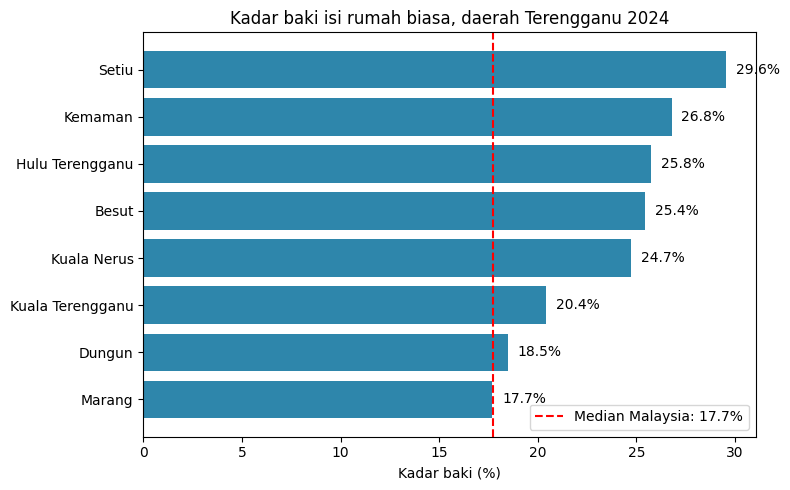

In [18]:
import matplotlib.pyplot as plt

trg = terkini[terkini["state"] == "Terengganu"].sort_values("kadar_baki_median")
median_my = terkini["kadar_baki_median"].median()

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(trg["district"], trg["kadar_baki_median"], color="#2E86AB")
ax.axvline(median_my, color="red", linestyle="--", label=f"Median Malaysia: {median_my:.1f}%")
for i, v in enumerate(trg["kadar_baki_median"]):
    ax.text(v + 0.5, i, f"{v:.1f}%", va="center")
ax.set_xlabel("Kadar baki (%)")
ax.set_title("Kadar baki isi rumah biasa, daerah Terengganu 2024")
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig("carta_terengganu.png", dpi=150)
plt.show()

## Carta 1: Daerah Terengganu
Median kadar baki (berasaskan median pendapatan) bagi 162 daerah di Malaysia ialah 17.7%. 7 daripada 8 daerah Terengganu berada atas paras ini. Marang berada tepat di paras median. Setiu tertinggi (29.6%). Kuala Terengganu, ibu negeri, kedua terendah (20.4%).

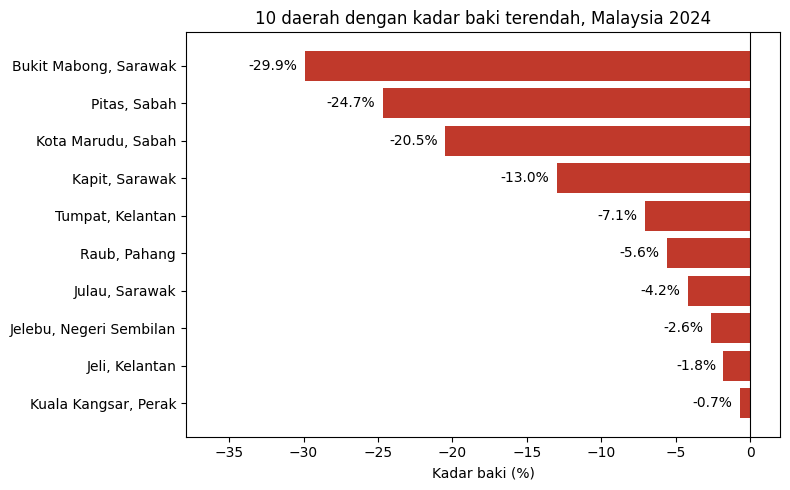

In [19]:
bawah = terkini.nsmallest(10, "kadar_baki_median").sort_values("kadar_baki_median", ascending=False)
label = bawah["district"] + ", " + bawah["state"]

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(label, bawah["kadar_baki_median"], color="#C0392B")
ax.axvline(0, color="black", linewidth=0.8)
for i, v in enumerate(bawah["kadar_baki_median"]):
    ax.text(v - 0.5, i, f"{v:.1f}%", va="center", ha="right")
ax.set_xlim(bawah["kadar_baki_median"].min() - 8, 2)
ax.set_xlabel("Kadar baki (%)")
ax.set_title("10 daerah dengan kadar baki terendah, Malaysia 2024")
plt.tight_layout()
plt.savefig("carta_10_terendah.png", dpi=150)
plt.show()

## Carta 2: 10 daerah terendah
Isi rumah biasa di 10 daerah ini belanja lebih daripada pendapatan. Empat paling teruk di Sabah dan Sarawak (-13.0% hingga -29.9%). Enam di Semenanjung lebih hampir dengan sifar (-0.7% hingga -7.1%), termasuk dua daerah Kelantan: Tumpat dan Jeli.

In [20]:
s = state.sort_values("year")
tumbuh = s.groupby("state").agg(
    tahun_awal=("year", "first"),
    pendapatan_awal=("income_mean", "first"),
    tahun_akhir=("year", "last"),
    pendapatan_akhir=("income_mean", "last"),
)
tempoh = tumbuh["tahun_akhir"] - tumbuh["tahun_awal"]
tumbuh["kali_ganda"] = tumbuh["pendapatan_akhir"] / tumbuh["pendapatan_awal"]
tumbuh["pertumbuhan_tahunan"] = (tumbuh["kali_ganda"] ** (1 / tempoh) - 1) * 100
tumbuh.sort_values("pertumbuhan_tahunan", ascending=False).round(1)

,tahun_awal,pendapatan_awal,tahun_akhir,pendapatan_akhir,kali_ganda,pertumbuhan_tahunan
state,,,,,,
Terengganu,1970,173,2024,7627,44.1,7.3
Perlis,1970,140,2024,5996,42.8,7.2
Johor,1970,237,2024,9484,40.0,7.1
Kelantan,1970,151,2024,5265,34.9,6.8
Melaka,1970,265,2024,8686,32.8,6.7
Selangor,1970,421,2024,13296,31.6,6.6
Pulau Pinang,1970,292,2024,9152,31.3,6.6
Kedah,1970,189,2024,5793,30.7,6.5
Negeri Sembilan,1970,286,2024,7305,25.5,6.2


## Pertumbuhan pendapatan negeri, tahun awal hingga 2024
Negeri yang mula paling rendah tumbuh paling laju. Perlis (RM140), Kelantan (RM151) dan Terengganu (RM173) bermula di bawah. Selangor bermula tertinggi (RM421).

Jurang negeri kaya dan miskin mengecil sedikit. Pada 1970, Selangor 2.8 kali ganda Kelantan. Pada 2024, nisbah itu 2.5 kali ganda.

Tahun mula tidak sama. Sabah, Sarawak dan Kuala Lumpur bermula 1976. Putrajaya bermula 2007. Semakan seterusnya guna tempoh sama, 1976 hingga 2024.

In [21]:
banding = state[state["year"].isin([1976, 2024])].pivot_table(
    index="state", columns="year", values="income_mean"
)
banding = banding.dropna()
banding["kali_ganda"] = banding[2024] / banding[1976]
banding["pertumbuhan_tahunan"] = (banding["kali_ganda"] ** (1 / 48) - 1) * 100
banding.sort_values("pertumbuhan_tahunan", ascending=False).round(1)

year,1976,2024,kali_ganda,pertumbuhan_tahunan
state,,,,
Terengganu,339.0,7627.0,22.5,6.7
Kelantan,269.0,5265.0,19.6,6.4
Kedah,306.0,5793.0,18.9,6.3
Johor,513.0,9484.0,18.5,6.3
Selangor,735.0,13296.0,18.1,6.2
Perlis,338.0,5996.0,17.7,6.2
Sarawak,426.0,6947.0,16.3,6.0
Pulau Pinang,589.0,9152.0,15.5,5.9
Melaka,568.0,8686.0,15.3,5.8


## Pertumbuhan pendapatan negeri, 1976 hingga 2024
Tempoh sama untuk 14 negeri. Labuan dan Putrajaya tiada data 1976.
Terengganu tumbuh paling laju: 22.5 kali ganda, RM339 ke RM7,627, purata 6.7% setahun. Terengganu juga teratas bagi tempoh 1970 hingga 2024 (7.3% setahun).
Selangor bermula tertinggi (RM735) tetapi masih di tempat kelima. Kesan asas rendah tidak terangkan semua.
Sabah dan Pahang tumbuh paling perlahan (5.4% setahun).
Had: angka nominal, belum tolak inflasi.

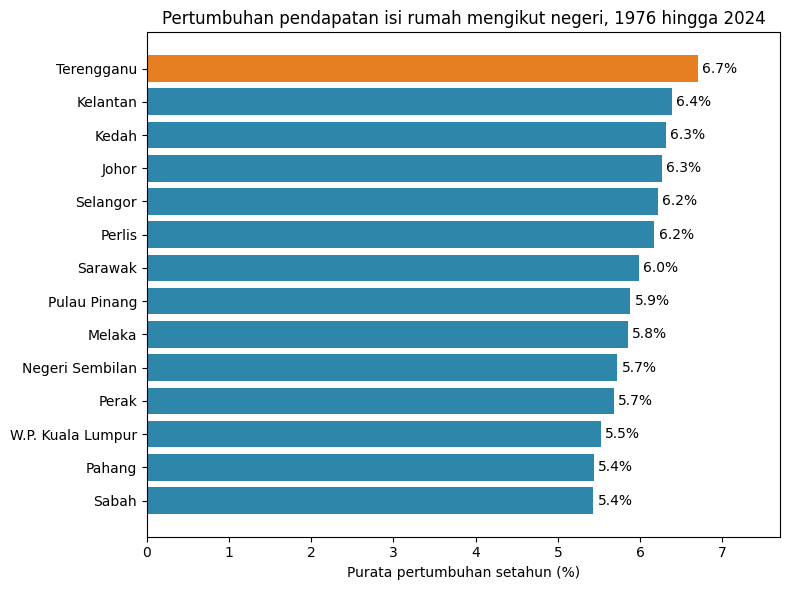

In [22]:
b = banding.sort_values("pertumbuhan_tahunan")
warna = ["#E67E22" if n == "Terengganu" else "#2E86AB" for n in b.index]

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(b.index, b["pertumbuhan_tahunan"], color=warna)
for i, v in enumerate(b["pertumbuhan_tahunan"]):
    ax.text(v + 0.05, i, f"{v:.1f}%", va="center")
ax.set_xlim(0, b["pertumbuhan_tahunan"].max() + 1)
ax.set_xlabel("Purata pertumbuhan setahun (%)")
ax.set_title("Pertumbuhan pendapatan isi rumah mengikut negeri, 1976 hingga 2024")
plt.tight_layout()
plt.savefig("carta_pertumbuhan_negeri.png", dpi=150)
plt.show()